# Antibiotic Resistance Trend Predictor

**How to run it:** put the four ICMR `.dta` files and `amr_trends.csv` in `data/raw/`, then choose *Restart* and *Run All*.
The cleaned files are saved in `data/processed/`.

| Part | What happens | Outcome |
|---|---|---|
| 1 | The problem, the data and the setup | CO1 |
| 2 | Sample data: load, inspect, fix dates | CO3 |
| 3 | Text columns: sets, regex, 0/1 columns | CO3 |
| 4 | Decode IDs, merge tables, fix data problems | CO3 |
| 5 | Explore the cleaned sample data | CO3 |
| 6 | Descriptive statistics and outliers | CO2, CO3 |
| 7 | Yearly trend data: load, clean, explore | CO3 |
| 8 | Summary and files saved | - |

### The data

| ICMR sample data (4 `.dta` files) | Real patient-level records: patients, hospital visits, samples and test results | Very small sample (10 patients) |
| `amr_trends.csv` | National yearly % susceptible for each organism and antibiotic, 2017 to 2024 | Large |



In [24]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# where the raw files are read from, and where cleaned files are saved
path = "../data/raw/"
output_path = "../data/processed/"

# make sure the output folder exists
os.makedirs(output_path, exist_ok=True)

### load and inspect 

The sample has four linked tables: patients, hospital visits, samples, and AMR test results.

#### Load the four tables

In [2]:
patients = pd.read_stata(path + "patient.dta")
visits = pd.read_stata(path + "patient2.dta")
samples = pd.read_stata(path + "patient3.dta")

# The results table is read without converting codes to names,
# because Stata stores some antibiotic labels twice (one for DISK, one for MIC).
# We decode the names ourselves in Part 4.
results = pd.read_stata(path + "patient4.dta", convert_categoricals=False)

print("patients:", patients.shape)
print("visits:  ", visits.shape)
print("samples: ", samples.shape)
print("results: ", results.shape)
print()
print("patients columns:", patients.columns.tolist())
patients.head()

patients: (10, 7)
visits:   (14, 11)
samples:  (16, 6)
results:  (140, 14)

patients columns: ['patient_id', 'gender', 'age', 'district', 'state', 'country', 'location_type']


,patient_id,gender,age,district,state,country,location_type
0,3541,male,32,Nellore,Andhra Pradesh,India,urban
1,9299,female,54,Chandigarh,Chandigarh,India,NaN
2,4823,female,47,Pondicherry,Puducherry,India,urban
3,12486,female,34,Pondicherry,Puducherry,India,urban
4,1064,male,49,Cuddalore,Tamil Nadu,India,urban


### Data Types And Missing Values


In [3]:
tables = {"patients": patients, "visits": visits, "samples": samples, "results": results}

for name, table in tables.items():
    print("==", name, table.shape, "==")
    print(table.dtypes)
    print("Missing values (NaN) per column:")
    print(table.isna().sum())

    empty_text = {}
    null_text = {}
    for col in table.columns:
        empty_count = (table[col] == "").sum()
        null_count = (table[col] == "NULL").sum()
        if empty_count > 0:
            empty_text[col] = int(empty_count)
        if null_count > 0:
            null_text[col] = int(null_count)
    print("Empty text cells:", empty_text)
    print("Cells containing the word NULL:", null_text)
    print()

== patients (10, 7) ==
patient_id          int32
gender           category
age                 int16
district         category
state            category
country          category
location_type    category
dtype: object
Missing values (NaN) per column:
patient_id       0
gender           0
age              0
district         0
state            0
country          0
location_type    1
dtype: int64
Empty text cells: {}
Cells containing the word NULL: {}

== visits (14, 11) ==
hospital_patient_rel_id       int32
hospital_id                    int8
patient_id                    int32
admission_date                  str
hospital_dept_id           category
ward_type                  category
infection_type_id          category
clinical_diagnosis              str
comorbidity                     str
devices_used                    str
prior_admission            category
dtype: object
Missing values (NaN) per column:
hospital_patient_rel_id     0
hospital_id                 0
patient_id          

#### Converting text data into Dates

In [4]:
print("Before:", samples["collection_date"].dtype, "|", visits["admission_date"].dtype)

samples["collection_date"] = pd.to_datetime(samples["collection_date"])
visits["admission_date"] = pd.to_datetime(visits["admission_date"])

print("After: ", samples["collection_date"].dtype, "|", visits["admission_date"].dtype)
print("Samples were collected from", samples["collection_date"].min().date(),
      "to", samples["collection_date"].max().date())

Before: str | str
After:  datetime64[us] | datetime64[us]
Samples were collected from 2023-02-24 to 2023-12-28


#### Text data handling.

In [5]:
print(visits["clinical_diagnosis"].tolist())
print(visits["comorbidity"].tolist())
print(visits["devices_used"].tolist())
print(samples["prescribed_antibiotic"].tolist())

['', '', '', 'Renal transplantation', 'ASTHMA MILD HAEMOPHILIA', 'NULL', 'NULL', 'NULL', '', '', 'phemphigus vulgaris', 'phemphigus vulgaris', '', '']
['', '', '', '', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']
['', '', '', 'Mechanical ventilator', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']
['', '', 'Inj. Magnex 2 gm,Tab. minocycline 200 mg', '', 'Inj. amikain 750 mg,Inj. Meropenem 2 gm', 'Inj. amikacin 750 mg,Inj. meropenum 2 gm', '', 'NULL', 'NULL', 'NULL', '', '', '', '', '', '']


#### Text Cleaning
functions
- clean_text_cell turns NaN, empty text and the word NULL into an empty string.
- split_clean splits one cell at the commas and returns a set of clean items.
- clean_antibiotic uses regular expressions to remove prefixes (Inj., Tab.) and doses (750 mg, 2 gm), then fixes spellings.

In [6]:
spelling_fixes = {
    "amikain": "amikacin",
    "meropenum": "meropenem",
}


def clean_text_cell(text):
    # turns NaN, empty text and "NULL" into an empty string
    if pd.isna(text):
        return ""
    text = text.strip().lower()
    if text == "null":
        return ""
    return text


def split_clean(text):
    # splits one cell at the commas and returns a set of clean items
    text = clean_text_cell(text)
    text = text.replace("phemphigus", "pemphigus")   # fix a spelling mistake
    items = set()
    if text == "":
        return items
    for piece in text.split(","):
        piece = piece.strip()
        if piece != "":
            items.add(piece)
    return items


def clean_antibiotic(item):
    item = re.sub(r"^(inj|tab)\.\s*", "", item)               # remove "inj." or "tab." at the start
    item = re.sub(r"\s*\d+(\.\d+)?\s*(mg|gm|g)\b", "", item)  # remove doses like 750 mg or 2 gm
    item = item.strip()
    if item in spelling_fixes:
        item = spelling_fixes[item]
    return item


def get_antibiotics(text):
    names = set()
    for piece in split_clean(text):
        name = clean_antibiotic(piece)
        if name != "":
            names.add(name)
    return names


samples["antibiotic_set"] = samples["prescribed_antibiotic"].apply(get_antibiotics)
print(samples[["sample_id", "prescribed_antibiotic", "antibiotic_set"]].to_string())

    sample_id                     prescribed_antibiotic         antibiotic_set
0      519724                                                               {}
1      520597                                                               {}
2      536921  Inj. Magnex 2 gm,Tab. minocycline 200 mg  {minocycline, magnex}
3      538192                                                               {}
4      539643   Inj. amikain 750 mg,Inj. Meropenem 2 gm  {amikacin, meropenem}
5      539645  Inj. amikacin 750 mg,Inj. meropenum 2 gm  {amikacin, meropenem}
6      566587                                                               {}
7      568935                                      NULL                     {}
8      571738                                      NULL                     {}
9      571748                                      NULL                     {}
10     580725                                                               {}
11     581846                                       

#### Turn text into 0/1 columns
1 if the row has that item, 0 if not.


In [7]:
def add_indicator_columns(table, set_column, prefix):
    # adds one 0/1 column for every distinct item found in the sets
    all_items = set()
    for row_items in table[set_column]:
        all_items.update(row_items)

    new_columns = []
    for item in sorted(all_items):
        column_name = prefix + item.replace(" ", "_")
        values = []
        for row_items in table[set_column]:
            if item in row_items:
                values.append(1)
            else:
                values.append(0)
        table[column_name] = values
        new_columns.append(column_name)
    return new_columns


# antibiotics (already cleaned into sets)
rx_columns = add_indicator_columns(samples, "antibiotic_set", "prescribed_")

# diagnosis and devices (split and cleaned here)
visits["diagnosis_set"] = visits["clinical_diagnosis"].apply(split_clean)
visits["device_set"] = visits["devices_used"].apply(split_clean)

dx_columns = add_indicator_columns(visits, "diagnosis_set", "dx_")
device_columns = add_indicator_columns(visits, "device_set", "device_")

print(samples[rx_columns].sum())
print()
print(visits[dx_columns + device_columns].sum())

prescribed_amikacin       2
prescribed_magnex         1
prescribed_meropenem      2
prescribed_minocycline    1
dtype: int64

dx_asthma_mild_haemophilia      1
dx_pemphigus_vulgaris           2
dx_renal_transplantation        1
device_mechanical_ventilator    1
dtype: int64


#### Mapping id to their names
The result code `remarks` means: 1 = Susceptible, 2 = Intermediate, 3 = Resistant.

In [8]:
with pd.read_stata(path + "patient4.dta", iterator=True) as reader:
    labels = reader.value_labels()

print(labels.keys())

results["antibiotic"] = results["antibiotic_id"].map(labels["antibiotic_id"])
results["organism"] = results["organism_id"].map(labels["organism_id"])
results["result"] = results["remarks"].map({1: "Susceptible", 2: "Intermediate", 3: "Resistant"})

print(results[["antibiotic", "organism", "value", "result"]].head(10))

dict_keys(['antibiotic_id', 'special_test_id', 'special_test_type', 'organism_id', 'panel_id', 'identification_method', 'remarks'])
                antibiotic               organism value        result
0                 Amikacin  Klebsiella pneumoniae    25   Susceptible
1               Cefotaxime  Klebsiella pneumoniae    25  Intermediate
2              Ceftazidime  Klebsiella pneumoniae    24   Susceptible
3              Ceftriaxone  Klebsiella pneumoniae    27   Susceptible
4            Ciprofloxacin  Klebsiella pneumoniae    26   Susceptible
5                 Imipenem  Klebsiella pneumoniae    27   Susceptible
6                Meropenem  Klebsiella pneumoniae    28   Susceptible
7  Piperacillin-tazobactam  Klebsiella pneumoniae    27   Susceptible
8                 Amikacin  Enterobacter cloacae     22   Susceptible
9               Cefotaxime  Enterobacter cloacae      6     Resistant


#### Merge results and samples  on sample_id.
is_resistant is 1 for Resistant and 0 otherwise (Intermediate counts as 0).

In [9]:
data = results.merge(samples[["sample_id", "collection_date"]], on="sample_id")

data["month"] = data["collection_date"].dt.to_period("M")
data["is_resistant"] = (data["result"] == "Resistant").astype(int)

print(data.shape)
print(data[["collection_date", "month", "antibiotic", "organism", "result", "is_resistant"]].head())

(140, 20)
  collection_date    month     antibiotic               organism  \
0      2023-02-24  2023-02       Amikacin  Klebsiella pneumoniae   
1      2023-02-24  2023-02     Cefotaxime  Klebsiella pneumoniae   
2      2023-02-24  2023-02    Ceftazidime  Klebsiella pneumoniae   
3      2023-02-24  2023-02    Ceftriaxone  Klebsiella pneumoniae   
4      2023-02-24  2023-02  Ciprofloxacin  Klebsiella pneumoniae   

         result  is_resistant  
0   Susceptible             0  
1  Intermediate             0  
2   Susceptible             0  
3   Susceptible             0  
4   Susceptible             0  


#### Dropping a Row with no S/I/R

In [10]:
print(data["result"].value_counts(dropna=False))
print()
print(data[data["result"].isna()][["sample_id", "antibiotic", "organism", "value", "remarks"]])

data = data.dropna(subset=["result"])
print(data.shape)

result
Susceptible     70
Resistant       60
Intermediate     9
NaN              1
Name: count, dtype: int64

     sample_id antibiotic               organism     value  remarks
108     586234        NaN  Staphylococcus aureus  Negative      NaN
(139, 20)


#### Removing the same antibiotic testing data-Duplicates

In [11]:
keys = ["sample_id", "organism", "antibiotic"]

# which sample / organism / antibiotic combinations appear more than once
dups = data.groupby(keys).size()
print(dups[dups > 1])

# look at one sample that was tested by two methods
example_id = dups[dups > 1].index[0][0]
print()
print("Sample", example_id)
print(data[data["sample_id"] == example_id][["antibiotic", "susceptibility_test_type", "value", "result"]].to_string())

sample_id  organism                      antibiotic                   
520597     Enterobacter cloacae          Amikacin                         2
                                         Ceftriaxone                      2
                                         Ciprofloxacin                    2
                                         Imipenem                         2
                                         Meropenem                        2
                                         Piperacillin-tazobactam          2
593721     Burkholderia cepacia complex  Ceftazidime                      2
                                         Meropenem                        2
                                         Minocycline                      2
                                         Trimethoprim-sulfamethoxazole    2
dtype: int64

Sample 520597
                 antibiotic  susceptibility_test_type value       result
8                  Amikacin                       2.0    22  Suscept

In [12]:
# 1. Do any duplicate tests disagree with each other?
check = data.groupby(keys)["remarks"].agg(["min", "max"])
print("Duplicate tests that disagree:")
print(check[check["min"] != check["max"]])

# 2. Keep one result per sample / organism / antibiotic (the highest code: 3 = Resistant)
clean = data.groupby(keys, as_index=False).agg(
    remarks=("remarks", "max"),
    collection_date=("collection_date", "first"),
    month=("month", "first")
)
clean["is_resistant"] = (clean["remarks"] == 3).astype(int)

print()
print("Rows before and after:", data.shape[0], "->", clean.shape[0])

clean.to_csv(output_path + "clean_results.csv", index=False)

Duplicate tests that disagree:
Empty DataFrame
Columns: [min, max]
Index: []

Rows before and after: 139 -> 129


#### Spread

remarks
Susceptible     65
Resistant       55
Intermediate     9
Name: count, dtype: int64


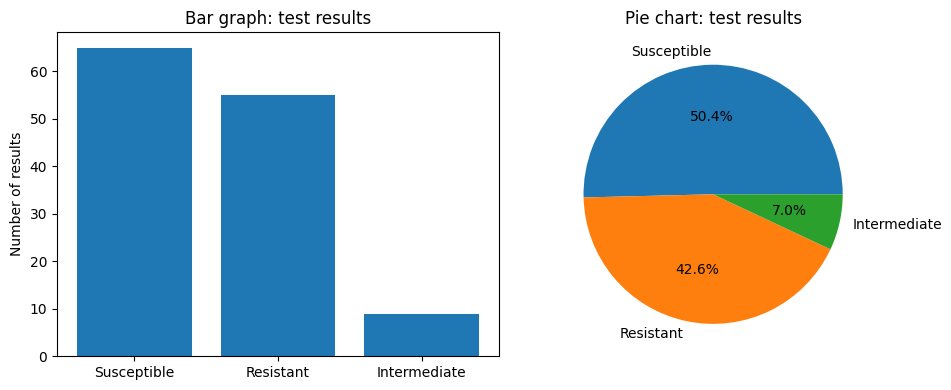

In [13]:
result_names = {1: "Susceptible", 2: "Intermediate", 3: "Resistant"}
result_counts = clean["remarks"].map(result_names).value_counts()
print(result_counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(result_counts.index, result_counts.values)
axes[0].set_title("Bar graph: test results")
axes[0].set_ylabel("Number of results")

axes[1].pie(result_counts.values, labels=result_counts.index, autopct="%1.1f%%")
axes[1].set_title("Pie chart: test results")

plt.tight_layout()
plt.show()

#### Resistance of antibiotic and resistance

In [14]:
by_antibiotic = clean.groupby("antibiotic")["is_resistant"].agg(["count", "sum"])
by_antibiotic = by_antibiotic.rename(columns={"count": "tested", "sum": "resistant"})
by_antibiotic["percent_resistant"] = by_antibiotic["resistant"] / by_antibiotic["tested"] * 100
print(by_antibiotic.sort_values("percent_resistant", ascending=False).round(1).to_string())

                               tested  resistant  percent_resistant
antibiotic                                                         
Ertapenem                           3          3              100.0
Cefepime                            3          2               66.7
Cefotaxime                         11          6               54.5
Imipenem                           15          8               53.3
Piperacillin-tazobactam            15          8               53.3
Ciprofloxacin                      14          7               50.0
Ceftazidime                         8          4               50.0
Meropenem                          16          8               50.0
Ceftriaxone                         8          3               37.5
Amikacin                           14          5               35.7
Levofloxacin                        4          1               25.0
Cefoxitin                           1          0                0.0
Colistin                            4          0

                              tested  resistant  percent_resistant
organism                                                          
Klebsiella pneumoniae             44         14               31.8
Escherichia coli                  31         20               64.5
Pseudomonas aeruginosa            17          0                0.0
Acinetobacter baumannii           15         13               86.7
Enterobacter cloacae               9          8               88.9
Staphylococcus aureus              8          0                0.0
Burkholderia cepacia complex       5          0                0.0

organism
Acinetobacter baumannii         2
Burkholderia cepacia complex    1
Enterobacter cloacae            1
Escherichia coli                4
Klebsiella pneumoniae           6
Pseudomonas aeruginosa          2
Staphylococcus aureus           1
Name: sample_id, dtype: int64


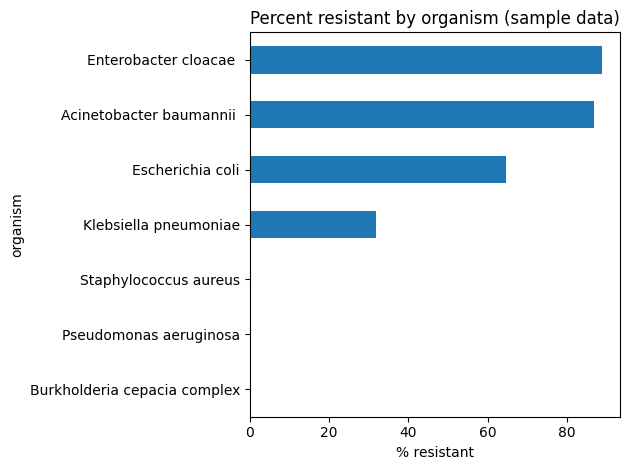

In [15]:
by_organism = clean.groupby("organism")["is_resistant"].agg(["count", "sum"])
by_organism = by_organism.rename(columns={"count": "tested", "sum": "resistant"})
by_organism["percent_resistant"] = by_organism["resistant"] / by_organism["tested"] * 100
print(by_organism.sort_values("tested", ascending=False).round(1).to_string())
print()

# how many samples (not tests) each organism came from
print(clean.groupby("organism")["sample_id"].nunique())

by_organism["percent_resistant"].sort_values().plot(kind="barh")
plt.xlabel("% resistant")
plt.title("Percent resistant by organism (sample data)")
plt.tight_layout()
plt.show()

#### merging mixed growth bacterium into one sample

In [16]:
per_sample = clean.groupby(["sample_id", "organism"]).agg(
    tested=("is_resistant", "count"),
    resistant=("is_resistant", "sum")
).reset_index()

per_sample["percent_resistant"] = per_sample["resistant"] / per_sample["tested"] * 100
print(per_sample.round(1).to_string())

    sample_id                      organism  tested  resistant  percent_resistant
0      519724         Klebsiella pneumoniae       8          0                0.0
1      520597         Enterobacter cloacae        9          8               88.9
2      536921              Escherichia coli       7          6               85.7
3      538192         Klebsiella pneumoniae       8          7               87.5
4      539643      Acinetobacter baumannii        8          7               87.5
5      539645        Pseudomonas aeruginosa       8          0                0.0
6      566587        Pseudomonas aeruginosa       9          0                0.0
7      568935      Acinetobacter baumannii        7          6               85.7
8      571738              Escherichia coli       8          7               87.5
9      571748              Escherichia coli       8          7               87.5
10     571748         Klebsiella pneumoniae       7          6               85.7
11     580725   

A bacterium is marked highly_resistant if it was resistant to more than 50% of the antibiotics tested.


In [17]:
info = per_sample.merge(samples[["sample_id", "hospital_patient_rel_id", "patient_id"]], on="sample_id")
info = info.merge(visits[["hospital_patient_rel_id", "ward_type", "infection_type_id"]], on="hospital_patient_rel_id")
info = info.merge(patients[["patient_id", "age", "gender"]], on="patient_id")

info["highly_resistant"] = (info["percent_resistant"] > 50).astype(int)

print(info.shape)
print(info[["sample_id", "organism", "percent_resistant", "ward_type", "infection_type_id", "age", "gender"]].round(1).to_string())
print()
print("unique patients:", info["patient_id"].nunique())
print()

for col in ["ward_type", "infection_type_id"]:
    group_summary = info.groupby(col)["highly_resistant"].agg(["count", "sum"])
    group_summary = group_summary.rename(columns={"count": "bacteria_rows", "sum": "highly_resistant"})
    print(group_summary)
    print()

(17, 12)
    sample_id                      organism  percent_resistant ward_type                 infection_type_id  age  gender
0      519724         Klebsiella pneumoniae                0.0       OPD      Community Acquired Infection   49    male
1      520597         Enterobacter cloacae                88.9      Ward  Health Care Associated Infection   51    male
2      536921              Escherichia coli               85.7       ICU  Health Care Associated Infection   47  female
3      538192         Klebsiella pneumoniae               87.5       OPD      Community Acquired Infection   47  female
4      539643      Acinetobacter baumannii                87.5       ICU  Health Care Associated Infection   47  female
5      539645        Pseudomonas aeruginosa                0.0       ICU  Health Care Associated Infection   47  female
6      566587        Pseudomonas aeruginosa                0.0       OPD                         Not Known   32    male
7      568935      Acinetobacte

#### Central Tendency Measures


In [18]:
ages = patients["age"]

mean = np.mean(ages)
median = np.median(ages)
mode = ages.mode().tolist()
value_range = ages.max() - ages.min()
variance = ages.var(ddof=0)
std_dev = np.sqrt(variance)

print("Mean:", round(mean, 2))
print("Median:", median)
print("Mode:", mode)
print("Range:", value_range)
print("Variance:", round(variance, 2))
print("Standard deviation:", round(std_dev, 2))
print("Skewness:", round(ages.skew(), 2))
print("Kurtosis:", round(ages.kurt(), 2))
print()
print(ages.describe())

Mean: 39.7
Median: 43.5
Mode: [1, 29, 32, 34, 40, 47, 49, 51, 54, 60]
Range: 59
Variance: 258.81
Standard deviation: 16.09
Skewness: -1.31
Kurtosis: 2.26

count    10.000000
mean     39.700000
std      16.957791
min       1.000000
25%      32.500000
50%      43.500000
75%      50.500000
max      60.000000
Name: age, dtype: float64


#### Histogram, box plot and outliers


IQR: 18.0 | bounds: 5.5 to 77.5
IQR outliers: [1]
Z-scores: [-0.48, 0.89, 0.45, -0.35, 0.58, 1.26, 0.02, -0.67, -2.41, 0.7]
Z-score outliers (|z| > 3): []


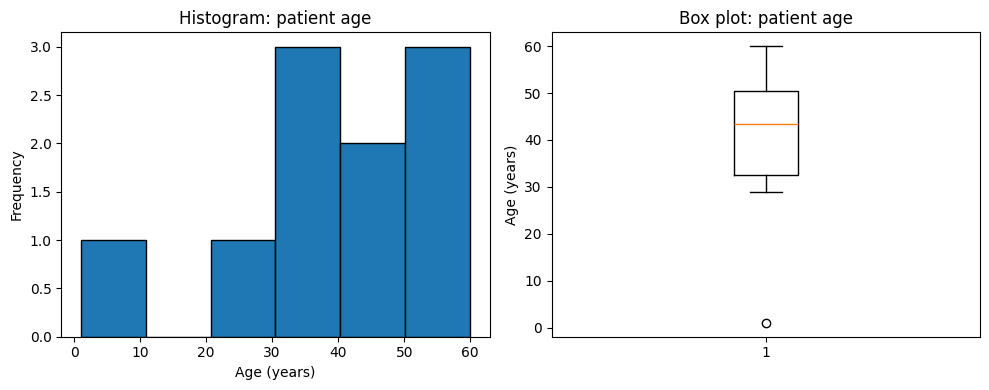

In [19]:
# IQR method
q1 = ages.quantile(0.25)
q3 = ages.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("IQR:", iqr, "| bounds:", lower, "to", upper)
print("IQR outliers:", ages[(ages < lower) | (ages > upper)].tolist())

# Z-score method
z_scores = (ages - ages.mean()) / ages.std(ddof=0)
print("Z-scores:", z_scores.round(2).tolist())
print("Z-score outliers (|z| > 3):", ages[abs(z_scores) > 3].tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(ages, bins=6, edgecolor="black")
axes[0].set_title("Histogram: patient age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(ages)
axes[1].set_title("Box plot: patient age")
axes[1].set_ylabel("Age (years)")

plt.tight_layout()
plt.show()

#### ICMR-AMRSN annual report tables (2017 to 2024).


### 7.1 Load and inspect

In [20]:
trends = pd.read_csv(path + "amr_trends.csv")

print(trends.shape)
print(trends.columns.tolist())
trends.head()

(1286, 13)
['organism', 'antibiotic', 'year', 'susceptible_n', 'tested_n', 'susceptible_pct', 'source_report_year', 'source_table', 'source_url', 'extracted_date', 'reported_pct', 'computed_pct', 'flags']


,organism,antibiotic,year,susceptible_n,tested_n,susceptible_pct,source_report_year,source_table,source_url,extracted_date,reported_pct,computed_pct,flags
0,Acinetobacter baumannii,amikacin,2017,638,3312,19.3,2022,Table 5.6,https://www.icmr.gov.in/icmrobject/custom_data...,2026-08-26,19.3,19.26,NaN
1,Acinetobacter baumannii,amikacin,2017,638,3312,19.3,2023,Table 4.3,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,19.3,19.26,NaN
2,Acinetobacter baumannii,amikacin,2017,638,3312,19.3,2024,Table 3.6,https://www.icmr.gov.in/icmrobject/uploads/Rep...,2026-08-26,19.3,19.26,NaN
3,Acinetobacter baumannii,amikacin,2018,877,3795,23.1,2022,Table 5.6,https://www.icmr.gov.in/icmrobject/custom_data...,2026-08-26,23.1,23.11,NaN
4,Acinetobacter baumannii,amikacin,2018,877,3795,23.1,2023,Table 4.3,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,23.1,23.11,NaN


#### Cleaning 

In [21]:
# 1. Keep only the newest report edition for each organism / antibiotic / year
trends = trends.sort_values("source_report_year")
trends_latest = trends.drop_duplicates(subset=["organism", "antibiotic", "year"], keep="last")

# 2. Drop colistin (its numbers are intermediate %, not susceptibility)
trends_latest = trends_latest[trends_latest["antibiotic"].str.lower() != "colistin"]

# 3. Checks
print(trends.shape, "->", trends_latest.shape)
print(trends_latest["susceptible_pct"].isna().sum(), "rows have no percentage")
print(trends_latest["flags"].value_counts(dropna=False))
print(trends_latest.groupby("organism")["antibiotic"].nunique())

# 4. Keep only rows that have a percentage, and save the cleaned data
trends_ok = trends_latest.dropna(subset=["susceptible_pct"])
trends_ok.to_csv(output_path + "clean_trends.csv", index=False)

(1286, 13) -> (478, 13)
12 rows have no percentage
flags
NaN                                                                       466
low_isolate_count_asterisk,pct_suppressed_in_source                        10
pct_suppressed_in_source                                                    1
low_isolate_count_asterisk,no_isolates_tested,pct_suppressed_in_source      1
Name: count, dtype: int64
organism
Acinetobacter baumannii     8
Escherichia coli           10
Klebsiella pneumoniae      10
MRSA                       11
Pseudomonas aeruginosa     10
Staphylococcus aureus      11
Name: antibiotic, dtype: int64


In [22]:
# 1. Organism/antibiotic pairs that don't have all 8 years
years_per_pair = trends_latest.groupby(["organism", "antibiotic"])["year"].nunique()
print(years_per_pair[years_per_pair < 8])

# 2. The MRSA antibiotic list
print(sorted(trends_latest[trends_latest["organism"] == "MRSA"]["antibiotic"].unique()))

organism  antibiotic   
MRSA      cotrimoxazole    7
          linezolid        7
Name: year, dtype: int64
['cefoxitin', 'ciprofloxacin', 'clindamycin', 'cotrimoxazole', 'erythromycin', 'linezolid', 'oxacillin', 'teicoplanin', 'tetracycline', 'tigecycline', 'vancomycin']


#### Susceptibility of Klebsiella pneumoniae and meropenem

     year  susceptible_n  tested_n  susceptible_pct
569  2017           2478      5147             48.1
572  2018           3832      7591             50.5
575  2019           6081     12164             50.0
578  2020           3660      7771             47.1
581  2021           5707     12678             45.0
584  2022           6404     14619             43.8
586  2023           2764      7335             37.6
587  2024           4276     12189             35.1


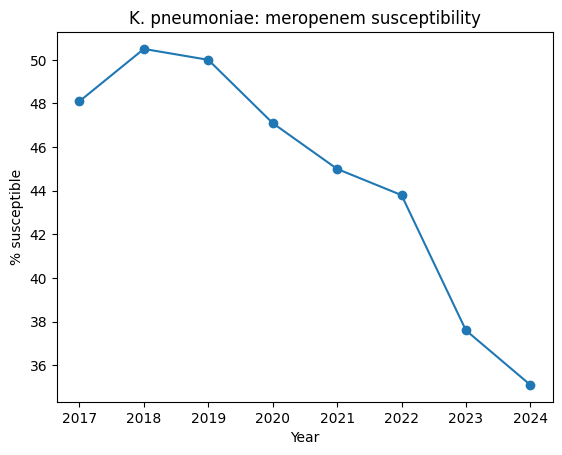

In [23]:
one_pair = trends_ok[(trends_ok["organism"] == "Klebsiella pneumoniae") & (trends_ok["antibiotic"] == "meropenem")]
one_pair = one_pair.sort_values("year")
print(one_pair[["year", "susceptible_n", "tested_n", "susceptible_pct"]])

plt.plot(one_pair["year"], one_pair["susceptible_pct"], marker="o")
plt.xlabel("Year")
plt.ylabel("% susceptible")
plt.title("K. pneumoniae: meropenem susceptibility")
plt.show()

## Part 8: Summary
**What we did (CO1 to CO3)**
1. Defined the problem and the two data sources (Part 1).
2. Loaded and inspected the sample tables, and fixed the date columns (Part 2).
3. Cleaned the text columns with sets and regular expressions, and made 0/1 columns (Part 3).
4. Decoded the IDs, merged the tables, dropped a bad row and removed duplicate tests (Part 4).
5. Explored the cleaned sample with charts and group tables (Part 5).
6. Measured the centre, spread and outliers of patient age (Part 6).
7. Loaded and cleaned the yearly trend data and looked at one trend (Part 7).

**Files saved** (in `data/processed/`): `clean_results.csv` and `clean_trends.csv`.

**Next (not in this notebook):** forecasting and the early-warning table (CO4, CO5).